# Replication notebook: *When Artificial Intelligence Makes Entrepreneurial Imagination Programmable*

Erik Lang and Nicolai J. Foss

This notebook accompanies our comment and re-analyses the records Felipe Csaszar released with *Conceptual Search: A Generative View of Entrepreneurial Imagination* (Strategic Entrepreneurship Journal, 2026, [doi.org/10.1002/sej.70055](https://doi.org/10.1002/sej.70055)), available at [github.com/fcsaszar/conceptual-search](https://github.com/fcsaszar/conceptual-search) under the MIT license.

- **Data.** Csaszar's files, downloaded from the repository at commit `4244604` (21 September 2026), its only commit as of 26 October 2026. Every file is checked against the repository's git hash before use.
- **Methods.** Counting, string comparison, medians, rank and partial rank correlations, and a bootstrap. No model calls. The default run takes about a minute and needs pandas, numpy, scipy and matplotlib.
- **Optional.** Section 5 reproduces the paper's semantic distances with its BGE-M3 embedding model (about 2.3 GB, plus `sentence-transformers` and `torch`); the comment's distances between population members, and from the withheld originals to their nearest seed, come from it. Set `RUN_EMBEDDINGS = True` to run it.

Section 2 recomputes the paper's headline numbers and the figures of Csaszar's robustness report that Sections 2.2 and 2.3 of the comment use. Sections 3 and 4 document the comment's first two points:
1. The 15 concepts of global search's final generation are, with two exceptions, variants of one concept (Section 2.1 of the comment; Figure 1 is drawn in Section 3).
2. The paper's two robustness judges agree with its main judge on the 30 originals, but place most of the gain in recombination rather than in polishing (Section 2.2 of the comment; Figure 2 is drawn in Section 4).

Section 6 supports the length results in Sections 2.2 and 2.3 of the comment and gives the bootstrap interval of Section 2.3.

In [61]:
import ast, csv, hashlib, importlib.util, json, re, sys, urllib.request
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from scipy import stats

OWNER_REPO = "fcsaszar/conceptual-search"
COMMIT = "4244604ba74d21c91f99125986100d286c30faa0"
RUN = "2026-08-08_deepseekv32-evalrank15-full"
CACHE = Path("csaszar_repo")   # the files are downloaded here
FIGS = Path("figures")         # figures produced by this notebook
RUN_EMBEDDINGS = False         # True: also run section 5 (downloads the 2.3 GB BGE-M3 model)

FIGS.mkdir(exist_ok=True)
csv.field_size_limit(sys.maxsize)
pd.set_option("display.max_colwidth", 150)
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
                     "font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6})
INK, MID, LIGHT, RED = "#222222", "#8a8a8a", "#d9d9d9", "#9e2a2b"

## 0. Download and verify Csaszar's files

Each file is fetched from the repository at the pinned commit and compared with the git hash the repository records for that file. A file that differs in a single byte fails the check.

In [62]:
FILES = {
    "in/projects.csv": "2d45225d910cb9728237048021064aba906b463a",
    "in/firm-set-15-evalrank.txt": "d752c8121a2e414a25f43cdc8be84435791c9121",
    "in/polish-seeds.csv": "c8ae45880b6db58e856379148361cd5a11b6ee3d",
    "out/2026-08-08_deepseekv32-evalrank15-full-global-candidates.csv": "81241cca660850115594ba8e52f8412b3a1c955e",
    "out/2026-08-08_deepseekv32-evalrank15-full-global-search.log": "71e302266bbd2fab9840734f5a0704e490d0cb9d",
    "out/2026-08-08_deepseekv32-evalrank15-full-universe-common-quality.csv": "383ccdc4e7a5fba744fc114dd6336e6152aeb761",
    "robustness1-gemma3-4b/inputs/concepts.csv": "5e6288e3cee2e7876e3a759c4a61bcf619ea0f06",
    "robustness1-gemma3-4b/outputs/2026-08-14-gemma3-4b-full/scores.csv": "f74fda0a6d76115557ce9d8545fa5e12b0b3490f",
    "robustness2-qwen2.5-72b/outputs/2026-08-14-qwen2.5-72b-full/scores.csv": "6633762ecc3f147f07d02505886eee0f6daf99fe",
    "robustness2-qwen2.5-72b/outputs/2026-08-14-qwen2.5-72b-full/cross-evaluator-comparison.json": "7a7266e2a076cb70a446a34680559bd5a57f05d4",
    "src/semantic_novelty.py": "23e852dede82b87420dfaa0b22e7652946a93841",
    "src/global_search.py": "f93dc388f8a0ebd81ba178ddf87d31f0093a8a0b",
}
OPTIONAL_FILES = {
    "out/2026-08-08_deepseekv32-evalrank15-full-semantic-scores.csv": "ca214a47d101f4fb00690122a2fa0e1d36cbdf6a",
    "out/2026-08-08_deepseekv32-evalrank15-full-polish-semantic-scores.csv": "d62c9e46632bc912840496952c140e7e5fd3419c",
    "out/2026-08-08_deepseekv32-evalrank15-full-baseline15-semantic-scores.csv": "ef577fd7db38d232bac32655b687d5c18dc6071a",
}


def git_blob_sha(data):
    return hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()


def fetch(path, sha):
    local = CACHE / path
    if not (local.exists() and git_blob_sha(local.read_bytes()) == sha):
        url = f"https://raw.githubusercontent.com/{OWNER_REPO}/{COMMIT}/{path}"
        local.parent.mkdir(parents=True, exist_ok=True)
        local.write_bytes(urllib.request.urlopen(url, timeout=120).read())
    return git_blob_sha(local.read_bytes()) == sha


needed = {**FILES, **(OPTIONAL_FILES if RUN_EMBEDDINGS else {})}
failed = [p for p, sha in needed.items() if not fetch(p, sha)]
assert not failed, f"hash mismatch: {failed}"
print(f"{len(needed)} files from {OWNER_REPO} at commit {COMMIT[:7]}: all identical to the repository.")

12 files from fcsaszar/conceptual-search at commit 4244604: all identical to the repository.


## 1. The data

- `in/projects.csv`: the 30 real Kickstarter campaigns (the originals) that form the reference set, with the money each raised. Search starts from the weaker half, the 15 seeds; the other 15 are the withheld originals.
- `in/polish-seeds.csv`: the 15 concepts of global search's final generation, as they entered the polishing stage.
- `robustness1-gemma3-4b/inputs/concepts.csv`: the frozen set of 75 texts that all three judges scored, with DeepSeek's win rates.
- The two robustness `scores.csv` files: Gemma 3 4B's and Qwen 2.5 72B's win rates for the same 75 texts.
- `out/...-global-candidates.csv` and `...-global-search.log`: every concept in every generation of global search, and the run log.
- `out/...-universe-common-quality.csv`: every distinct concept of the run with its win rate against the 30 originals, the performance measure of the paper's figures.

In [63]:
def path(p):
    return CACHE / p


projects = pd.read_csv(path("in/projects.csv"))
seed_ids = [l.strip() for l in open(path("in/firm-set-15-evalrank.txt")) if l.strip() and not l.startswith("#")]
final = pd.read_csv(path("in/polish-seeds.csv"))
frozen = pd.read_csv(path("robustness1-gemma3-4b/inputs/concepts.csv"))
gemma = pd.read_csv(path("robustness1-gemma3-4b/outputs/2026-08-14-gemma3-4b-full/scores.csv"))
qwen = pd.read_csv(path("robustness2-qwen2.5-72b/outputs/2026-08-14-qwen2.5-72b-full/scores.csv"))
cand = pd.read_csv(path(f"out/{RUN}-global-candidates.csv"))
quality = pd.read_csv(path(f"out/{RUN}-universe-common-quality.csv"))
quality = dict(zip(quality.plan_text.map(lambda t: " ".join(t.split())), quality.benchmark_quality))
cand["reference-set win rate"] = cand.plan_text.map(lambda t: quality[" ".join(t.split())])
reported = json.load(open(path("robustness2-qwen2.5-72b/outputs/2026-08-14-qwen2.5-72b-full/cross-evaluator-comparison.json")))

spec = importlib.util.spec_from_file_location("semantic_novelty", path("src/semantic_novelty.py"))
sn = importlib.util.module_from_spec(spec)
sys.modules["semantic_novelty"] = sn
spec.loader.exec_module(sn)   # Csaszar's section-to-component mapping


def stage(row):
    if row["group"] == "original":
        return "seed" if str(row["is_seed"]).lower() == "true" else "withheld original"
    return {"global_final": "recombined", "polished": "recombined, polished", "local_only": "local-only final"}[row["group"]]


frozen["stage"] = frozen.apply(stage, axis=1)
qcol = [c for c in qwen.columns if c.startswith("qwen") and c.endswith("win_rate")][0]
wr = frozen.set_index("slot_id")[["stage", "lineage_id", "parent_slot_id", "deepseek_win_rate"]].copy()
wr["gemma_win_rate"] = gemma.set_index("slot_id")["gemma_win_rate"]
wr["qwen_win_rate"] = qwen.set_index("slot_id")[qcol]
J = {"DeepSeek": "deepseek_win_rate", "Gemma": "gemma_win_rate", "Qwen": "qwen_win_rate"}
print(f"{len(projects)} originals, {len(seed_ids)} of them seeds; {len(final)} concepts in the final generation; "
      f"{len(wr)} texts scored by all three judges")
wr.groupby("stage").size().rename("texts").to_frame()

30 originals, 15 of them seeds; 15 concepts in the final generation; 75 texts scored by all three judges


,texts
stage,
local-only final,15
recombined,15
"recombined, polished",15
seed,15
withheld original,15


## 2. Reported numbers, recomputed

Win rates are shares of pairwise judgments won against the 30 originals, counting both presentation orders. The column "Reported by Csaszar" gives the number in the paper or in Csaszar's cross-evaluator report; "Recomputed here" recomputes it from the files above.

In [64]:
orig = wr[wr.stage.isin(["seed", "withheld original"])]
raised = projects.set_index("id")["raised"]
pol = wr[wr.stage == "recombined, polished"]
parent = wr.loc[pol.parent_slot_id]
local = wr[wr.stage == "local-only final"]
distinct = wr[~frozen.text_sha256.duplicated().values]
generated = distinct[~distinct.stage.isin(["seed", "withheld original"])]
med = lambda s, j="DeepSeek": wr.loc[wr.stage == s, J[j]].median()
gain = {j: 100 * np.median(pol[J[j]].values - parent[J[j]].values) for j in J}
seed_max = {j: wr.loc[wr.stage == "seed", J[j]].max() for j in J}
cf, cc = reported["fundraising_correlations"], reported["claim_comparison"]["polish_median_delta_percentage_points"]
outrank, cg = reported["claim_comparison"]["polished_above_all_fixed_seeds"], reported["correlations"]["all_generated_unique_texts"]
rows = [
    ("Seed median win rate, DeepSeek", "paper, section 3.4", "33%", f"{med('seed'):.1%}"),
    ("Polished-slate median win rate, DeepSeek", "paper, section 3.4", "63%", f"{med('recombined, polished'):.1%}"),
    ("Local-only median and best win rate, DeepSeek", "paper, section 3.5", "68% and 90%",
     f"{med('local-only final'):.1%} and {local.deepseek_win_rate.max():.1%}"),
    ("Polished concepts that beat their parent, DeepSeek", "paper, section 3.4", "all fifteen",
     f"{int((pol.deepseek_win_rate.values > parent.deepseek_win_rate.values).sum())} of 15"),
    ("Agreement on the 30 originals, DeepSeek-Gemma and DeepSeek-Qwen", "paper, appendix C.9", "0.94 and 0.82",
     " and ".join(f"{stats.spearmanr(orig.deepseek_win_rate, orig[J[j]])[0]:.2f}" for j in ("Gemma", "Qwen"))),
    ("Rank correlation with money raised, DeepSeek, Gemma, Qwen", "robustness report",
     ", ".join(f"{cf[k]:.2f}" for k in ("deepseek", "gemma", "qwen")),
     ", ".join(f"{stats.spearmanr(orig[J[j]], raised.loc[orig.lineage_id])[0]:.2f}" for j in J)),
    ("Median gain from polishing in points, DeepSeek, Gemma, Qwen", "robustness report",
     ", ".join(f"{cc[k]:.1f}" for k in ("deepseek", "gemma", "qwen")), ", ".join(f"{gain[j]:.1f}" for j in J)),
    ("Polished concepts that outrank every seed, DeepSeek, Gemma, Qwen", "robustness report",
     ", ".join(str(outrank[k]) for k in ("deepseek", "gemma", "qwen")),
     ", ".join(str(int((pol[J[j]] > seed_max[j]).sum())) for j in J)),
    (f"Agreement on the {len(generated)} distinct generated texts, DeepSeek-Gemma and DeepSeek-Qwen", "robustness report",
     f"{cg['deepseek_gemma']:.2f} and {cg['deepseek_qwen']:.2f}",
     " and ".join(f"{stats.spearmanr(generated.deepseek_win_rate, generated[J[j]])[0]:.2f}" for j in ("Gemma", "Qwen"))),
]
pd.DataFrame(rows, columns=["Quantity", "Source", "Reported by Csaszar", "Recomputed here"])

,Quantity,Source,Reported by Csaszar,Recomputed here
0,"Seed median win rate, DeepSeek","paper, section 3.4",33%,32.8%
1,"Polished-slate median win rate, DeepSeek","paper, section 3.4",63%,63.3%
2,"Local-only median and best win rate, DeepSeek","paper, section 3.5",68% and 90%,68.3% and 90.0%
3,"Polished concepts that beat their parent, DeepSeek","paper, section 3.4",all fifteen,15 of 15
4,"Agreement on the 30 originals, DeepSeek-Gemma and DeepSeek-Qwen","paper, appendix C.9",0.94 and 0.82,0.94 and 0.82
5,"Rank correlation with money raised, DeepSeek, Gemma, Qwen",robustness report,"0.66, 0.60, 0.51","0.66, 0.60, 0.51"
6,"Median gain from polishing in points, DeepSeek, Gemma, Qwen",robustness report,"28.3, 5.0, 8.3","28.3, 5.0, 8.3"
7,"Polished concepts that outrank every seed, DeepSeek, Gemma, Qwen",robustness report,"15, 15, 9","15, 15, 9"
8,"Agreement on the 44 distinct generated texts, DeepSeek-Gemma and DeepSeek-Qwen",robustness report,0.02 and 0.47,0.02 and 0.47


## 3. Finding 1: the final generation is largely one concept

The paper reports that polishing lifted all fifteen concepts of global search's final generation and that "every polished descendant outranks every seed". The fifteen concepts are in `in/polish-seeds.csv`. Their one-sentence summaries:

In [65]:
def section(text, name):
    text = re.sub(r"^\s*---.*---\s*$", "", text, flags=re.M)
    m = re.search(r"^#+ *" + re.escape(name) + r" *\n(.*?)(?=^#|\Z)", text, flags=re.S | re.M)
    return m.group(1) if m else ""


norm = lambda s: " ".join(s.split())
final["summary"] = [norm(section(t, "One-Sentence Summary")) for t in final.description]
final["win rate before polish"] = [wr.loc[f"global-final:{i}", "deepseek_win_rate"] for i in final.id]
final["after polish"] = [wr.loc[f"polished:{i}", "deepseek_win_rate"] for i in final.id]
g12_novelty = {t.strip(): n for t, n in zip(cand[cand.step == 12].plan_text, cand[cand.step == 12].novelty)}
final["distance to nearest seed (recorded)"] = [round(g12_novelty[t.strip()], 3) for t in final.description]
final[["id", "summary", "win rate before polish", "after polish", "distance to nearest seed (recorded)"]]

,id,summary,win rate before polish,after polish,distance to nearest seed (recorded)
0,g12-s00,"A privacy-first platform that generates verifiable digital fingerprints of ethical sourcing events and anchors them to a public, tamper-proof ledg...",0.3833,0.6833,0.337
1,g12-s01,"A privacy-first platform that creates permanent, verifiable digital fingerprints of ethical sourcing events anchored to a public ledger, building ...",0.2833,0.5333,0.335
2,g12-s02,"A mobile app that aggregates local yard, estate, and community sales on a single live map, plans efficient routes, and adds game-like rewards to t...",0.3500,0.6333,0.030
3,g12-s03,"A privacy-first platform that generates verifiable digital fingerprints of ethical sourcing events and anchors them to a public, tamper-proof ledg...",0.3667,0.5500,0.335
4,g12-s04,"A privacy-first platform that generates verifiable digital fingerprints of ethical sourcing events and anchors them to a public, tamper-proof ledg...",0.4000,0.7333,0.332
5,g12-s05,"A privacy-first platform that generates verifiable digital fingerprints of ethical sourcing events and anchors them to a public, tamper-proof ledg...",0.4000,0.6667,0.332
6,g12-s06,"A privacy-first platform that creates permanent, verifiable digital fingerprints of ethical sourcing events anchored to a public ledger, building ...",0.2667,0.6167,0.335
7,g12-s07,"A privacy-first platform that creates permanent, verifiable digital fingerprints of ethical sourcing events anchored to a public ledger, building ...",0.2833,0.6333,0.338
8,g12-s08,"A platform that provides verifiable proof of ethical sourcing by creating a permanent, independently verifiable record anchored to a public ledger...",0.3500,0.7000,0.336
9,g12-s09,"A privacy-first platform that generates verifiable digital fingerprints of ethical sourcing events and anchors them to a public, tamper-proof ledg...",0.3833,0.7000,0.341


### Word-for-word identical sections

Fourteen of the fifteen concepts are Markdown texts with the same seven headings; the yard-sale app keeps the layout of the originals. The next cell compares every section across the fifteen concepts, once after collapsing whitespace (same words) and once byte for byte. Sections count as identical after dropping the `--- BEGIN PROJECT ---` and `--- END PROJECT ---` lines that some texts contain.

In [66]:
SECTIONS = ["One-Sentence Summary", "Problem", "Target Users & Use Cases", "Solution / Product Overview",
            "Delivery Model", "Revenue Logic", "Distinctiveness"]
SIX = SECTIONS[1:]   # the sections that hold the paper's six components
raw = {i: {s: section(t, s) for s in SECTIONS} for i, t in zip(final.id, final.description)}
table = []
for s in SECTIONS:
    words, exact = Counter(norm(raw[i][s]) for i in raw), Counter(raw[i][s] for i in raw)
    table.append((s, len(words), words.most_common(1)[0][1], exact.most_common(1)[0][1]))
display(pd.DataFrame(table, columns=["Section", "Distinct texts among the 15", "Largest group with the same words",
                                     "Largest byte-identical group"]))
common = {s: Counter(norm(raw[i][s]) for i in raw).most_common(1)[0][0] for s in SECTIONS}
shared = pd.Series({i: sum(norm(raw[i][s]) == common[s] for s in SIX) for i in raw})
print("Concepts with the most common text in all six components:", int((shared == 6).sum()))
shared.value_counts().sort_index(ascending=False).rename("concepts").rename_axis("components identical to the most common text (of 6)").to_frame()

,Section,Distinct texts among the 15,Largest group with the same words,Largest byte-identical group
0,One-Sentence Summary,9,5,5
1,Problem,5,11,11
2,Target Users & Use Cases,5,8,8
3,Solution / Product Overview,5,11,11
4,Delivery Model,5,11,11
5,Revenue Logic,4,11,11
6,Distinctiveness,5,11,6


Concepts with the most common text in all six components: 4


,concepts
components identical to the most common text (of 6),
6,4
5,5
4,3
2,1
0,2


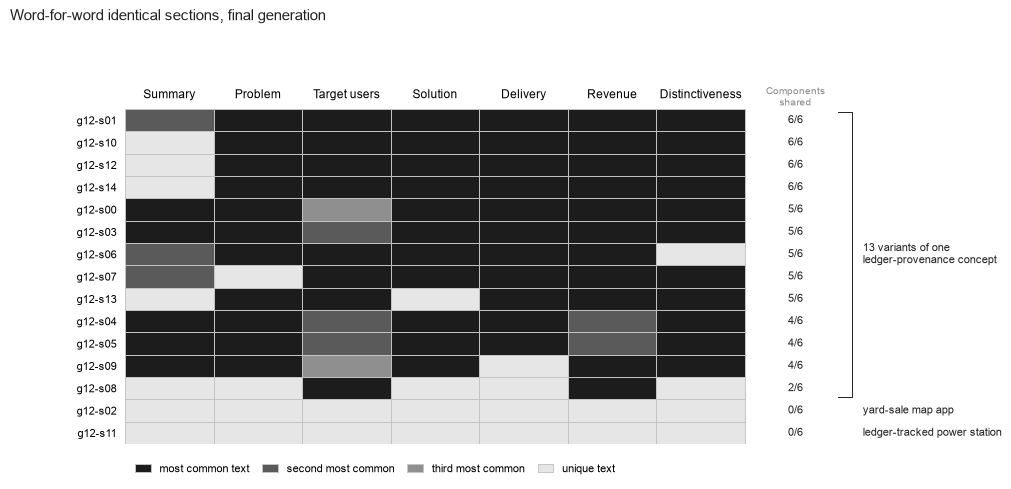

In [67]:
LABEL = {"g12-s02": "yard-sale map app", "g12-s11": "ledger-tracked power station"}
COLS = ["Summary", "Problem", "Target users", "Solution", "Delivery", "Revenue", "Distinctiveness"]
rank = {}
for s in SECTIONS:
    order = [t for t, c in Counter(norm(raw[i][s]) for i in raw).most_common() if c > 1]
    for i in raw:
        t = norm(raw[i][s])
        rank[(i, s)] = order.index(t) if t in order else None
ids = sorted(raw, key=lambda i: (-shared[i], i))
fills = {0: "#1c1c1c", 1: "#5a5a5a", 2: "#8f8f8f"}
UNIQUE, EDGE = "#e6e6e6", "#c4c4c4"


def draw_identical_sections(ax, title, raise_title=False):
    count_x, ann_x = 7.15, 8.05
    for r, i in enumerate(ids):
        for c, s in enumerate(SECTIONS):
            k = rank[(i, s)]
            ax.add_patch(Rectangle((c, r), 1, 1, facecolor=fills[k] if k is not None else UNIQUE,
                                   edgecolor=EDGE, linewidth=0.7))
        ax.text(count_x + 0.42, r + 0.5, f"{shared[i]}/6", va="center", ha="center", fontsize=8, color=INK)
    family = [r for r, i in enumerate(ids) if i not in LABEL]
    top, bottom = min(family) + 0.12, max(family) + 0.88
    ax.plot([ann_x, ann_x + 0.16, ann_x + 0.16, ann_x], [top, top, bottom, bottom], color=INK, lw=0.7,
            clip_on=False)
    ax.text(ann_x + 0.28, (top + bottom) / 2, f"{len(family)} variants of one\nledger-provenance concept",
            va="center", ha="left", fontsize=8, color=INK)
    for r, i in enumerate(ids):
        if i in LABEL:
            ax.text(ann_x + 0.28, r + 0.5, LABEL[i], va="center", ha="left", fontsize=8, color=INK)
    ax.set_xlim(0, count_x + 0.9)
    ax.set_ylim(len(ids), 0)
    ax.set_xticks([c + 0.5 for c in range(7)])
    ax.set_xticklabels(COLS, fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_yticks([r + 0.5 for r in range(len(ids))])
    ax.set_yticklabels(ids, fontsize=8)
    ax.tick_params(length=0, pad=6)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.text(count_x + 0.42, -0.55, "Components\nshared", ha="center", va="center", fontsize=7.5, color=MID,
            linespacing=1.05)
    handles = [Rectangle((0, 0), 1, 1, facecolor=fills[k], edgecolor=EDGE, linewidth=0.7) for k in (0, 1, 2)]
    handles.append(Rectangle((0, 0), 1, 1, facecolor=UNIQUE, edgecolor=EDGE, linewidth=0.7))
    ax.legend(handles, ["most common text", "second most common", "third most common", "unique text"],
              ncol=4, fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(0.0, -0.03),
              handlelength=1.4, columnspacing=1.15)
    if raise_title:
        fig = ax.figure
        fig.subplots_adjust(top=0.78)
        fig.text(0.0, 0.98, title, ha="left", va="top", fontsize=11, color=INK)
    else:
        ax.set_title(title, loc="left", fontsize=9, pad=16, color=INK)


fig, ax = plt.subplots(figsize=(9.2, 5.0))
draw_identical_sections(ax, "Word-for-word identical sections, final generation", raise_title=True)
fig.savefig(FIGS / "figure1_identical_sections.png", dpi=220, bbox_inches="tight", facecolor="white")
plt.show()

### How the final generation was produced

Each generation holds five unchanged elites, five mutations and five crossovers. The paper describes a mutation as a change to one of a concept's six components "while preserving the other five", and says that "at most two elites may come from any one seed's family ... so no family monopolizes survival." The code (`select_elites_with_lineage_cap` in `src/global_search.py`, printed further below) counts a recombined concept against the cap of every founding seed among its ancestors, and adds a fallback the paper does not describe: "top up by rank if the cap cannot fill all slots." The run log records every generation in which the cap intervened. The next cell lists, for each such generation, the concepts the cap displaced and admitted, with their selection rank in the generation and their win rate against the 30 originals.

In [68]:
g12 = cand[cand.step == 12].sort_values("slot")
display(g12["transformation"].value_counts().rename("slots in the final generation").to_frame())
display(g12.assign(**{"founding seeds": g12.root_lineage})[["slot", "transformation", "founding seeds"]].set_index("slot"))
def describe(step, names):
    pop = cand[cand.step == step].set_index("candidate_id")
    return "; ".join(f"{n if len(n) <= 40 else n[:37] + '...'} (rank {int(pop.loc[n, 'selection_rank'])}, "
                     f"{pop.loc[n, 'reference-set win rate']:.0%})" for n in names)


cap, step = [], None
for line in open(path(f"out/{RUN}-global-search.log"), encoding="utf-8"):
    m = re.search(r"Step (\d+)/12", line)
    if m:
        step = int(m.group(1))
    if "Lineage cap" in line:
        displaced = ast.literal_eval(re.search(r"displaced (\[.*?\]), admitted", line).group(1))
        admitted = ast.literal_eval(re.search(r"admitted (\[.*\])", line).group(1))
        cap.append((step + 1, describe(step, displaced), describe(step, admitted)))
pd.DataFrame(cap, columns=["building generation", "displaced by the cap (selection rank, win rate)",
                           "admitted by the cap (selection rank, win rate)"]).set_index("building generation")

,slots in the final generation
transformation,
elite,5
mutation,5
crossover,5


,transformation,founding seeds
slot,,
0,elite,"angelry,clockchain,hply,lockguard"
1,elite,"angelry,clockchain,genaix,hply,lockguard"
2,elite,sale-finder
3,elite,"angelry,clockchain,hply,lockguard"
4,elite,"angelry,clockchain,hply,lockguard"
5,mutation,"angelry,clockchain,hply,lockguard"
6,mutation,"angelry,clockchain,genaix,hply,lockguard"
7,mutation,"angelry,clockchain,genaix,hply,lockguard"
8,mutation,"angelry,clockchain,genaix,hply,lockguard"


,"displaced by the cap (selection rank, win rate)","admitted by the cap (selection rank, win rate)"
building generation,,
3,"clockchain.M1.5.M2.3 (rank 3, 72%); (lockguardXclockchain).G1.2 (rank 4, 25%); ((lockguardXclockchain).G1.2Xhply.M1.... (rank 5, 40%)","(genaixXhply).G1.3.M2.4 (rank 8, 17%); sale-finder.M1.3 (rank 10, 37%); hply.M1.4 (rank 13, 52%)"
4,"clockchain.M1.5.M2.3.M3.2 (rank 4, 73%); clockchain.M1.5.M2.3.M3.4 (rank 5, 67%)","(genaixXhply).G1.3.M2.4 (rank 13, 17%); sale-finder.M1.3 (rank 15, 37%)"
5,"clockchain.M1.5.M2.3.M3.2.M4.4 (rank 5, 78%)","sale-finder.M1.3 (rank 15, 37%)"
6,"(clockchain.M1.5X((lockguardXclockcha... (rank 5, 30%)","sale-finder.M1.3 (rank 15, 37%)"
7,"clockchain.M1.5.M2.2.M4.1.M5.5 (rank 5, 75%)","sale-finder.M1.3 (rank 15, 37%)"
8,"clockchain.M1.5.M2.3.M3.2.M4.3.M5.2 (rank 5, 78%)","sale-finder.M1.3 (rank 13, 37%)"
9,"(clockchain.M1.5X((lockguardXclockcha... (rank 5, 45%)","sale-finder.M1.3 (rank 12, 37%)"
10,"((clockchain.M1.5.M2.5X((lockguardXcl... (rank 5, 32%)","sale-finder.M1.3 (rank 11, 37%)"
11,"((clockchain.M1.5.M2.5X((lockguardXcl... (rank 5, 33%)","sale-finder.M1.3 (rank 12, 37%)"


From generation 5 on, the cap displaced one concept per generation, always the fifth-ranked, and admitted `sale-finder.M1.3`, the yard-sale app (slot 2 above).

The paper illustrates the retention rule with a clockchain variant: "By generation 4, a mutation of clockchain had reached 78 percent, and elite slots kept it alive through generation 7", until it "was crowded out" as "distant hybrids rose in the tournament" (section 3.3). The next cell lists every concept of the clockchain family that reached 75 percent or more against the originals, with each generation it appeared in.

In [69]:
strong = cand[cand.root_lineage.map(lambda r: "clockchain" in str(r).split(","))
              & (cand["reference-set win rate"] >= 0.75)]
pd.DataFrame([{"concept": n, "win rate against the originals": f"{d['reference-set win rate'].iloc[0]:.0%}",
               "generations present (entry, selection rank)":
                   ", ".join(f"{s} ({t}, rank {int(r)})" for s, t, r in zip(d.step, d.transformation, d.selection_rank))}
              for n, d in strong.groupby("candidate_id", sort=False)]).set_index("concept")

,win rate against the originals,"generations present (entry, selection rank)"
concept,,
clockchain.M1.5.M2.3.M3.2.M4.4,78%,"4 (mutation, rank 5)"
clockchain.M1.5.M2.3.M3.2.M4.3.M5.2,78%,"5 (mutation, rank 3), 6 (elite, rank 2), 7 (elite, rank 5)"
clockchain.M1.5.M2.2.M4.1.M5.5,75%,"5 (mutation, rank 4), 6 (elite, rank 5)"
clockchain.M1.5.M2.2.M4.1.M5.5.M7.4,78%,"7 (mutation, rank 7)"


The concept from generation 4 that reached 78 percent never held an elite slot: ranked fifth, it was displaced by the cap when generation 5 was built. A second concept at 78 percent appeared in generation 5, held an elite slot in generations 6 and 7, and was displaced the same way when generation 8 was built. Both times the slot went to the yard-sale app, while the clockchain family kept four of the five elite slots (next cell).

The next cell runs Csaszar's `select_elites_with_lineage_cap` function, taken unchanged from `src/global_search.py`, on each generation's recorded selection ranking. It checks that the function reproduces the recorded elites, and counts how many elites share the most common founding seed. The cap allows two per founding seed. The last column counts how many of the five elite slots the cap fills on its own, before the top-up.

In [70]:
source = open(path("src/global_search.py"), encoding="utf-8").read()
node = next(n for n in ast.parse(source).body
            if isinstance(n, ast.FunctionDef) and n.name == "select_elites_with_lineage_cap")
print(ast.get_source_segment(source, node))
namespace = {}
exec(compile(ast.Module(body=[node], type_ignores=[]), "global_search.py", "exec"), namespace)
select_elites = namespace["select_elites_with_lineage_cap"]


def fill_by_cap_alone(order, roots, n_elites, cap):
    # the first loop of the function above, without the top-up
    counts, filled = Counter(), 0
    for i in order:
        if filled < n_elites and all(counts[s] < cap for s in roots[i]):
            counts.update(roots[i])
            filled += 1
    return filled


rows = []
for g in range(12):
    pop = cand[cand.step == g].reset_index(drop=True)
    order = pop.sort_values("selection_rank").index.tolist()
    roots = [frozenset(str(r).split(",")) for r in pop.root_lineage]
    chosen = select_elites(order, roots, 5, 2)
    recorded = cand[(cand.step == g + 1) & (cand.transformation == "elite")].parent_a
    counts = Counter(s for i in chosen for s in roots[i])
    over = sorted(((s, n) for s, n in counts.items() if n > 2), key=lambda x: (-x[1], x[0]))
    rows.append({"generation": g + 1,
                 "function reproduces the recorded elites": sorted(pop.candidate_id[i] for i in chosen) == sorted(recorded),
                 "founding seeds above the cap of 2 (number of elites carrying each)":
                     ", ".join(f"{s} {n}" for s, n in over) or "none",
                 "slots the cap fills without the top-up (of 5)": fill_by_cap_alone(order, roots, 5, 2)})
pd.DataFrame(rows).set_index("generation")

def select_elites_with_lineage_cap(
    sorted_indices: list[int],
    root_sets: list[frozenset[str]],
    n_elites: int,
    cap: int,
) -> list[int]:
    """Pick elites in selection-rank order, holding each founding lineage to at
    most ``cap`` elite slots; top up by rank if the cap cannot fill all slots."""
    chosen: list[int] = []
    lineage_counts: dict[str, int] = {}
    for index in sorted_indices:
        if len(chosen) == n_elites:
            break
        roots = root_sets[index]
        if all(lineage_counts.get(root, 0) < cap for root in roots):
            chosen.append(index)
            for root in roots:
                lineage_counts[root] = lineage_counts.get(root, 0) + 1
    if len(chosen) < n_elites:
        for index in sorted_indices:
            if index not in chosen:
                chosen.append(index)
                if len(chosen) == n_elites:
                    break
    return chosen


,function reproduces the recorded elites,founding seeds above the cap of 2 (number of elites carrying each),slots the cap fills without the top-up (of 5)
generation,,,
1,True,none,5
2,True,none,5
3,True,none,5
4,True,"clockchain 3, hply 3",4
5,True,"clockchain 4, hply 3, lockguard 3",3
6,True,clockchain 4,3
7,True,"clockchain 4, hply 3, lockguard 3",3
8,True,"clockchain 4, hply 4, lockguard 4",3
9,True,"angelry 4, clockchain 4, hply 4, lockguard 4",3


The function reproduces the recorded elites in every generation. From generation 4 on, more elites carry the founding seed `clockchain` than the cap allows: three in generation 4 and four in every later generation. In most of these generations `hply` and `lockguard` also exceed the cap, and from generation 9 `angelry` does too. The slots above the cap come from the top-up rule: without it, the cap could fill only four of the five slots in generation 4 and three in every later generation. Mutations and crossovers of these elites fill the rest of each generation.

### Diversity across generations

The paper's novelty measure is a concept's semantic distance to the nearest seed; its values are recorded in the candidates file. The next cell sets them beside two text-only measures of how alike the population members are. Both use the paper's mapping from sections to its six components.

,"median novelty (paper's measure, as recorded)",share of pairs with an identical Problem section,mean identical components per pair (of 6)
generation,,,
0,0.000,0.000,0.000
1,0.013,0.029,0.200
2,0.047,0.029,0.200
3,0.048,0.067,0.457
4,0.282,0.076,0.743
5,0.304,0.152,1.133
6,0.302,0.076,0.790
7,0.305,0.095,0.438
8,0.317,0.200,0.724


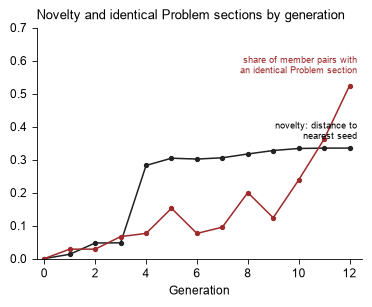

In [71]:
traj = []
for g, pop in cand.groupby("step"):
    comps = [{k: norm(v) for k, v in sn.component_texts(t).items()} for t in pop.plan_text]
    pairs = list(combinations(comps, 2))
    traj.append({"generation": g,
                 "median novelty (paper's measure, as recorded)": pop.novelty.median(),
                 "share of pairs with an identical Problem section": np.mean([a["problem"] == b["problem"] for a, b in pairs]),
                 "mean identical components per pair (of 6)": np.mean([sum(a[k] == b[k] for k in sn.COMPONENTS) for a, b in pairs])})
traj = pd.DataFrame(traj).set_index("generation")
display(traj.round(3))

fig, ax = plt.subplots(figsize=(4.2, 3))
ax.plot(traj.index, traj.iloc[:, 0], "-o", color=INK, ms=2.8, lw=1.1)
ax.plot(traj.index, traj.iloc[:, 1], "-o", color=RED, ms=2.8, lw=1.1)
ax.text(12.3, traj.iloc[-1, 0] + 0.02, "novelty: distance to\nnearest seed", ha="right", va="bottom", fontsize=6.5)
ax.text(12.3, traj.iloc[-1, 1] + 0.03, "share of member pairs with\nan identical Problem section", ha="right", va="bottom",
        fontsize=6.5, color=RED)
ax.set_xlim(-0.3, 12.5)
ax.set_ylim(0, 0.7)
ax.set_xticks(range(0, 13, 2))
ax.set_xlabel("Generation")
ax.set_title("Novelty and identical Problem sections by generation", loc="left", fontsize=9)
fig.savefig(FIGS / "supplementary_convergence.png", dpi=220, bbox_inches="tight")
plt.show()

### Novelty and layout

Every original has Development Status, Risks and Team sections. Crossover writes its children in a new layout without them. The next cell classifies every population entry of global search by layout and sets its recorded novelty beside it. It also shows the layout of the texts the three judges scored.

In [72]:
def layout(text):
    return "original" if re.search(r"#+\s*(Development Status|Risks|Team)", text) else "new"


cand["layout"] = cand.plan_text.map(layout)
frozen["layout"] = frozen.plan_text.map(layout)
print("Originals in the original layout:", sum(layout(t) == "original" for t in projects.description),
      "of", len(projects))
display(cand.groupby("layout").novelty.agg(["size", "min", "max"]).round(3)
        .rename(columns={"size": "population entries", "min": "lowest novelty", "max": "highest novelty"}))
pd.crosstab(frozen.stage, frozen.layout).rename_axis(index="texts scored by all three judges", columns="layout")

Originals in the original layout: 30 of 30


,population entries,lowest novelty,highest novelty
layout,,,
new,128,0.23,0.366
original,67,0.00,0.053


layout,new,original
texts scored by all three judges,,
local-only final,0,15
recombined,14,1
"recombined, polished",14,1
seed,0,15
withheld original,0,15


## 4. Finding 2: where the gain arises depends on the judge

The paper concludes that "global search's main effect is the creation of novelty, not immediate performance" and that refinement and recombination "are therefore complements rather than rivals". It also reports that both robustness judges "placed the polished slate's median above the local-only slate's".

Win-rate levels can differ between judges, so each comparison below stays within one judge. It traces the median win rate from the seeds through recombination to polishing, and compares it with polishing the seeds directly (the local-only finals).

In [73]:
stages = ["seed", "recombined", "recombined, polished", "local-only final", "withheld original"]
tab = pd.DataFrame({j: [wr.loc[wr.stage == s, c].median() for s in stages] for j, c in J.items()}, index=stages)
display((100 * tab).round(1).rename_axis("median win rate against the 30 originals (%)"))
steps = pd.DataFrame({j: {"recombination: seeds to recombined": tab.loc["recombined", j] - tab.loc["seed", j],
                          "polishing: recombined to polished": tab.loc["recombined, polished", j] - tab.loc["recombined", j],
                          "recombined and polished minus polished only": tab.loc["recombined, polished", j] - tab.loc["local-only final", j]}
                      for j in J})
display((100 * steps).round(1).rename_axis("change in median win rate (points)"))
agree = []
for a, b in (("DeepSeek", "Gemma"), ("DeepSeek", "Qwen"), ("Gemma", "Qwen")):
    for name, sub in (("30 originals", orig), ("15 local-only finals", local)):
        agree.append((f"{a} and {b}", name, round(stats.spearmanr(sub[J[a]], sub[J[b]])[0], 2)))
pd.DataFrame(agree, columns=["judges", "texts", "rank correlation"]).pivot(index="judges", columns="texts", values="rank correlation")

,DeepSeek,Gemma,Qwen
median win rate against the 30 originals (%),,,
seed,32.8,37.9,27.6
recombined,36.7,80.0,70.0
"recombined, polished",63.3,83.3,80.0
local-only final,68.3,55.0,63.3
withheld original,72.4,62.1,74.1


,DeepSeek,Gemma,Qwen
change in median win rate (points),,,
recombination: seeds to recombined,3.9,42.1,42.4
polishing: recombined to polished,26.7,3.3,10.0
recombined and polished minus polished only,-5.0,28.3,16.7


texts,15 local-only finals,30 originals
judges,,
DeepSeek and Gemma,0.81,0.94
DeepSeek and Qwen,0.78,0.82
Gemma and Qwen,0.74,0.87


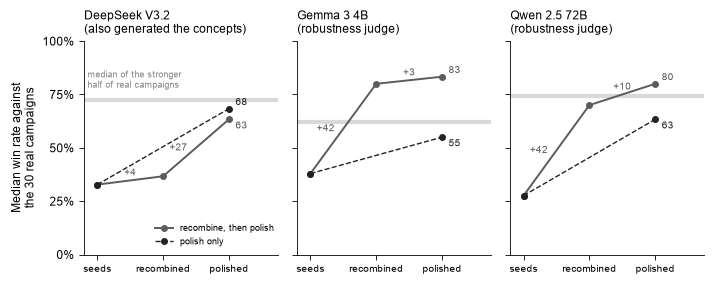

In [74]:
names = {"DeepSeek": "DeepSeek V3.2\n(also generated the concepts)", "Gemma": "Gemma 3 4B\n(robustness judge)",
         "Qwen": "Qwen 2.5 72B\n(robustness judge)"}
recombine = "#5c5c5c"
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9), sharey=True)
for ax, j in zip(axes, J):
    m = tab[j]
    ax.axhline(m["withheld original"], color=LIGHT, lw=3, zorder=0)
    ax.plot([0, 1, 2], [m["seed"], m["recombined"], m["recombined, polished"]], "-o", color=recombine, lw=1.4, ms=4,
            label="recombine, then polish")
    ax.plot([0, 2], [m["seed"], m["local-only final"]], "--o", color=INK, lw=1.0, ms=4, label="polish only")
    for x0, x1, y0, y1 in ((0, 1, m["seed"], m["recombined"]), (1, 2, m["recombined"], m["recombined, polished"])):
        steep = abs(y1 - y0) > 0.15
        ax.text((x0 + x1) / 2 - (0.13 if steep else 0), (y0 + y1) / 2 + (0 if steep else 0.035),
                f"{100 * (y1 - y0):+.0f}", color=recombine, fontsize=7, ha="right" if steep else "center", va="center")
    up = m["recombined, polished"] >= m["local-only final"]
    ax.text(2.1, m["recombined, polished"] + (0.03 if up else -0.03), f"{100 * m['recombined, polished']:.0f}",
            color=recombine, fontsize=7.5, va="center")
    ax.text(2.1, m["local-only final"] + (-0.03 if up else 0.03), f"{100 * m['local-only final']:.0f}",
            color=INK, fontsize=7.5, va="center")
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["seeds", "recombined", "polished"], fontsize=7.5)
    ax.set_xlim(-0.2, 2.75)
    ax.set_ylim(0, 1)
    ax.set_title(names[j], fontsize=8.5, loc="left")
axes[0].set_ylabel("Median win rate against\nthe 30 real campaigns")
axes[0].set_yticks([0, 0.25, 0.5, 0.75, 1])
axes[0].set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
axes[0].legend(fontsize=6.5, frameon=False, loc="lower right", bbox_to_anchor=(1.02, 0.0))
axes[0].text(-0.15, tab.loc["withheld original", "DeepSeek"] + 0.045, "median of the stronger\nhalf of real campaigns",
             fontsize=6.3, color=MID, va="bottom")
fig.tight_layout(w_pad=1.2)
fig.savefig(FIGS / "figure2_three_judges.png", dpi=220, bbox_inches="tight")
plt.show()

When DeepSeek, the model that also generated, selected and polished the concepts, is the judge, recombination adds little and polishing adds most, and polishing the seeds directly ends highest. Under both robustness judges, recombination produces most of the gain (42 points) and polishing adds less (3 and 10 points).

### What the judges agree on, and where they differ

The next cell compares, within each judge, every local-only final with its own seed, and every polished concept with the recombined concept it came from. For polishing it reports the share of the remaining room to improve that polishing closes: the gain divided by the distance from the recombined concept's win rate to 100 percent.

In [75]:
seed_slot = wr[wr.stage == "seed"].reset_index().set_index("lineage_id")["slot_id"]
seed_of_local = wr.loc[seed_slot[local.lineage_id].values]
rows = {}
for j, c in J.items():
    lift = local[c].values - seed_of_local[c].values
    room = np.where(parent[c].values < 1, (pol[c].values - parent[c].values) / (1 - parent[c].values), np.nan)
    rows[j] = {"local-only finals above their seed": f"{int((lift > 0).sum())} of {len(lift)}",
               "median gain of a local-only final over its seed (points)": round(100 * np.median(lift), 1),
               "median share of the remaining room closed by polishing": f"{np.nanmedian(room):.0%}"}
pd.DataFrame(rows)

,DeepSeek,Gemma,Qwen
local-only finals above their seed,15 of 15,15 of 15,15 of 15
median gain of a local-only final over its seed (points),38.3,16.6,28.4
median share of the remaining room closed by polishing,46%,21%,25%


The next cell compares the judges' rankings within each group of texts, counting repeated texts once, and sets the figures from Csaszar's cross-evaluator report beside them. The originals and the local-only finals are in the original layout; the recombined and polished concepts, except the yard-sale app, are in the new layout.

In [76]:
sha = frozen.set_index("slot_id")["text_sha256"]
lay = frozen.set_index("slot_id")["layout"]
rows = []
for name, st, key in (("originals", ["seed", "withheld original"], "originals"),
                      ("local-only finals", ["local-only final"], "local_only"),
                      ("recombined concepts", ["recombined"], "global_final"),
                      ("polished concepts", ["recombined, polished"], "polished")):
    sub = wr[wr.stage.isin(st)]
    sub = sub[~sha.loc[sub.index].duplicated().values]
    row = {"texts": f"{name} (n = {len(sub)})", "layout": lay.loc[sub.index].mode()[0]}
    for j in ("Gemma", "Qwen"):
        row[f"DeepSeek-{j}, recomputed"] = round(stats.spearmanr(sub.deepseek_win_rate, sub[J[j]])[0], 2)
        row[f"DeepSeek-{j}, Csaszar's report"] = round(reported["correlations"][key][f"deepseek_{j.lower()}"], 2)
    rows.append(row)
pd.DataFrame(rows).set_index("texts")

,layout,"DeepSeek-Gemma, recomputed","DeepSeek-Gemma, Csaszar's report","DeepSeek-Qwen, recomputed","DeepSeek-Qwen, Csaszar's report"
texts,,,,,
originals (n = 30),original,0.94,0.94,0.82,0.82
local-only finals (n = 15),original,0.81,0.81,0.78,0.78
recombined concepts (n = 14),new,0.42,0.42,0.09,0.09
polished concepts (n = 15),new,0.13,0.13,0.34,0.34


All three judges score every local-only final above its seed, and both robustness judges place the polished slate above the local-only slate. Self-preference alone cannot explain the pattern: DeepSeek gives the recombined and polished texts, which it wrote, lower scores than both robustness judges do, and higher scores only to the local-only finals, which keep the layout of the originals. Polishing was optimized against DeepSeek and closes a larger share of the remaining room under DeepSeek than under the other judges. The judges also rank the texts in the original layout alike. Their rankings agree less within the recombined and polished groups. Those groups consist mostly of variants of one concept, so the comparison cannot separate the new layout from the lack of distinct concepts.

Four limits apply. The medians summarize close variants of one concept, not fifteen independent concepts. Gemma 3 4B is a small model, so the weight rests on Qwen 2.5 72B agreeing with Gemma. Under the robustness judges the recombined concepts start high, which leaves polishing less room to register. And Gemma and Qwen scored texts that DeepSeek generated and selected; they did not re-run the search.

## 5. Optional: the paper's semantic distances with its embedding model

This section uses Csaszar's `SemanticNovelty` class with BGE-M3 at the revision the paper pins. It checks that the recorded novelty values are reproduced, measures how far the fifteen withheld originals lie from their nearest seed, repeats the diversity measure of Section 3 with semantic distance, and draws Figure 1 of the comment with a second panel for these distances (`figures/supplementary_figure1_with_distances.png`). It requires `pip install sentence-transformers torch` and downloads about 2.3 GB; it takes about three minutes on a laptop CPU.

A run of this section on 25 September 2026, with sentence-transformers 5.6.0 and torch 2.13.0 (the versions Csaszar pins), reported:
- All 45 recorded novelty values are reproduced; the largest difference is 2.0 × 10⁻⁷.
- The median distance from the 15 withheld originals to their nearest seed is 0.349. That is about the distance the paper reports for the recombined-and-polished slate (0.35), so 0.35 is about the distance between one original and another.
- The median semantic distance between population members falls from 0.41 in generation 0 to about 0.15 by generation 6 and to 0.04 in generation 12, the generation that was polished.

In [77]:
missing = [m for m in ("sentence_transformers", "torch") if importlib.util.find_spec(m) is None]
if not RUN_EMBEDDINGS:
    print("Skipped. Set RUN_EMBEDDINGS = True in the first code cell to run this section.")
elif missing:
    print(f"This kernel ({sys.executable}) does not have {' or '.join(missing)}.\n"
          "Install the versions Csaszar pins, then restart the kernel:\n"
          "    %pip install sentence-transformers==5.6.0 torch==2.13.0\n"
          "or switch the notebook to a Python environment that already has them.")
else:
    failed = [p for p, sha in OPTIONAL_FILES.items() if not fetch(p, sha)]
    assert not failed, f"hash mismatch: {failed}"
    text_of = projects.set_index("id")["description"]
    model = sn.SemanticNovelty(seed_ids, [text_of[s] for s in seed_ids], model_name="BAAI/bge-m3",
                               model_revision="5617a9f61b028005a4858fdac845db406aefb181", device="cpu")
    recorded = {}
    for name in ("semantic-scores", "polish-semantic-scores", "baseline15-semantic-scores"):
        df = pd.read_csv(path(f"out/{RUN}-{name}.csv"))
        recorded.update(dict(zip(df.plan_text, df.semantic_novelty)))
    gen = frozen[frozen.group.isin(["local_only", "global_final", "polished"])]
    ours = model.novelty_scores(list(gen.plan_text))
    diff = [abs(o - recorded[t]) for o, t in zip(ours, gen.plan_text) if t in recorded]
    print(f"Recorded novelty reproduced for {len(diff)} of {len(gen)} texts; largest difference {max(diff):.1e}")

    def mean_distance(a, b):
        return float(np.mean([1 - np.dot(x, y) for x, y in zip(a, b)]))

    seed_vecs = model.embed_plans([text_of[s] for s in seed_ids])
    withheld = [t for i, t in text_of.items() if i not in seed_ids]
    calib = np.median([min(mean_distance(v, s) for s in seed_vecs) for v in model.embed_plans(withheld)])
    print(f"Median distance from a withheld original to its nearest seed: {calib:.3f}")
    div = []
    for g, pop in cand.groupby("step"):
        vecs = model.embed_plans(list(pop.plan_text))
        div.append(np.median([mean_distance(a, b) for a, b in combinations(vecs, 2)]))
    traj["median semantic distance between members"] = div
    display(traj.round(3))

    fig = plt.figure(figsize=(13.4, 4.6))
    grid = fig.add_gridspec(1, 3, width_ratios=[2.3, 0.85, 1.05], wspace=0.08)
    draw_identical_sections(fig.add_subplot(grid[0]), "A. Word-for-word identical sections, final generation")
    ax2 = fig.add_subplot(grid[2])
    nov, dv = traj.iloc[:, 0], traj["median semantic distance between members"]
    ax2.plot(traj.index, nov, "-o", color=INK, ms=2.8, lw=1.1)
    ax2.plot(traj.index, dv, "-o", color=RED, ms=2.8, lw=1.1)
    ax2.axhline(calib, ls=(0, (3, 2)), color=MID, lw=0.8)
    ax2.text(12.3, calib + 0.012, "15 withheld originals\nto their nearest seed", fontsize=6.3, color=MID,
             va="bottom", ha="right")
    ax2.text(12.3, nov.iloc[-1] - 0.03, "novelty:\ndistance to\nnearest seed", fontsize=6.5, color=INK, va="top",
             ha="right")
    ax2.text(12.3, dv.iloc[-1] + 0.025, "diversity:\ndistance between\nmembers", fontsize=6.5, color=RED,
             va="bottom", ha="right")
    ax2.set_xlim(-0.3, 12.5)
    ax2.set_ylim(0, 0.5)
    ax2.set_xticks(range(0, 13, 2))
    ax2.set_xlabel("Generation")
    ax2.set_ylabel("Median semantic distance")
    ax2.set_title("B. Novelty and diversity by generation", loc="left", fontsize=9)
    fig.savefig(FIGS / "supplementary_figure1_with_distances.png", dpi=220, bbox_inches="tight")
    plt.show()

Skipped. Set RUN_EMBEDDINGS = True in the first code cell to run this section.


## 6. Text length, win rates and money raised

Longer texts win more often in the released records. The next cell measures this with the paper's win rates, for every concept the two searches produced or retained (the fifteen seeds included) and for the 30 originals. For the originals it also sets the length of the campaign summary against the money the campaign raised, beside DeepSeek's win rate, and then holds each constant in turn.

In [78]:
n_words = lambda t: len(t.split())
o = frozen[frozen.group == "original"]
o_len, o_win, o_raised = o.plan_text.map(n_words).values, o.deepseek_win_rate.values, raised.loc[o.lineage_id].values
r_len_win = stats.spearmanr(o_len, o_win).statistic
r_len_raised = stats.spearmanr(o_len, o_raised).statistic
r_win_raised = stats.spearmanr(o_win, o_raised).statistic
rows = [
    (f"Length and win rate, every concept of the two searches (n = {len(quality)})",
     stats.spearmanr([n_words(t) for t in quality], list(quality.values()))[0]),
    ("Length and DeepSeek win rate, 30 originals", r_len_win),
    ("Length and money raised, 30 originals", r_len_raised),
    ("DeepSeek win rate and money raised, 30 originals", r_win_raised),
]
display(pd.DataFrame(rows, columns=["quantity", "rank correlation"]).set_index("quantity").round(2))

def partial_rank(r_xy, r_xz, r_yz):
    # Partial correlation of x and y, holding z constant, from the three rank correlations.
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))

def partial_p(r, n, k=1):
    # Two-sided p-value. One variable is held constant, so df = n - 3.
    df = n - 2 - k
    t = r * np.sqrt(df / (1 - r**2))
    return 2 * stats.t.sf(abs(t), df)

n = len(o)
partials = [
    ("DeepSeek and money raised, holding length constant",
     partial_rank(r_win_raised, r_len_win, r_len_raised)),
    ("Length and money raised, holding DeepSeek constant",
     partial_rank(r_len_raised, r_len_win, r_win_raised)),
]
partials = pd.DataFrame(partials, columns=["quantity", "partial rank correlation"])
partials["two-sided p"] = [partial_p(r, n) for r in partials["partial rank correlation"]]
partials.set_index("quantity").round(3)

,rank correlation
quantity,
"Length and win rate, every concept of the two searches (n = 171)",0.85
"Length and DeepSeek win rate, 30 originals",0.71
"Length and money raised, 30 originals",0.66
"DeepSeek win rate and money raised, 30 originals",0.66


,partial rank correlation,two-sided p
quantity,,
"DeepSeek and money raised, holding length constant",0.364,0.052
"Length and money raised, holding DeepSeek constant",0.362,0.054


The next cell draws 10,000 bootstrap resamples of the 30 originals (random seed 42) and gives 95 percent intervals for the two rank correlations with the money raised and for their difference.

In [79]:
rng = np.random.default_rng(42)
boot = []
for _ in range(10_000):
    draw = rng.integers(0, n, n)
    r_win, r_len = stats.spearmanr(o_win[draw], o_raised[draw]).statistic, stats.spearmanr(o_len[draw], o_raised[draw]).statistic
    boot.append((r_win, r_len, r_win - r_len))
boot = np.array(boot)
interval = lambda x: f"{np.percentile(x, 2.5):.2f} to {np.percentile(x, 97.5):.2f}"
pd.DataFrame({"rank correlation with money raised": np.round([r_win_raised, r_len_raised, r_win_raised - r_len_raised], 2),
              "95% bootstrap interval": [interval(boot[:, k]) for k in range(3)]},
             index=["DeepSeek win rate", "length", "difference"]).rename_axis("30 originals")

,rank correlation with money raised,95% bootstrap interval
30 originals,,
DeepSeek win rate,0.66,0.38 to 0.84
length,0.66,0.41 to 0.81
difference,0.00,-0.26 to 0.24


On the 30 originals, the length of the campaign summary and DeepSeek's win rate each have a rank correlation of 0.66 with the money raised. The 95 percent bootstrap intervals are 0.38 to 0.84 for DeepSeek and 0.41 to 0.81 for length, and the interval for their difference, −0.26 to 0.24, includes zero. Holding length constant, DeepSeek's ranking keeps a partial rank correlation of 0.36 with the money raised; holding DeepSeek's ranking constant, length keeps 0.36. Both two-sided p-values are about 0.05. The validation therefore struggles to separate a judgment of a campaign's substance from features of the text that travel with its length.

### Length of the texts all three judges scored

The next cell gives the length of the 75 texts that all three judges scored, by stage, and each judge's rank correlation of length with win rate, counting repeated texts once: across all distinct texts, and across the distinct generated texts.

In [80]:
words = frozen.set_index("slot_id").plan_text.map(n_words)
display(words.groupby(wr.stage).agg(["median", "min", "max"]).loc[stages].rename_axis("words per text"))
pd.DataFrame({f"{name} (n = {len(sub)})": {j: round(stats.spearmanr(words.loc[sub.index], sub[c])[0], 2) for j, c in J.items()}
              for name, sub in (("all distinct texts", distinct), ("distinct generated texts", generated))}
             ).rename_axis("rank correlation of length and win rate")

,median,min,max
words per text,,,
seed,523.0,457,578
recombined,728.0,504,858
"recombined, polished",1177.0,710,1406
local-only final,1140.0,762,1454
withheld original,581.0,523,642


,all distinct texts (n = 74),distinct generated texts (n = 44)
rank correlation of length and win rate,,
DeepSeek,0.37,0.49
Gemma,0.48,-0.09
Qwen,0.47,0.26


Polishing lengthens the median recombined text from 728 to 1,177 words, and every polished and every local-only text is longer than every original (at least 710 words, against at most 642). All three judges favor longer texts across the 74 distinct texts, but among the 44 generated texts DeepSeek's win rate rises with length far more than Gemma's or Qwen's.

## Notes

- **Scope.** Everything above comes from one stochastic run, the run the paper reports.
- **Credit.** This re-analysis is possible only because Csaszar released complete records, code and robustness outputs.